# How missing roads change evacuation exits: a small test in Paradise, California

**Question.** If some streets are missing from a road map, how much does that change which exits look busiest, and how many homes can still reach an exit?

**Method.** I downloaded the Paradise, California road network from OpenStreetMap using OSMnx in Python. Intersections inside the town boundary are treated as "homes" and intersections outside it as "exits". Each home is routed to its nearest exit, and the homes using each exit are counted. I then removed 5%, 10%, 20%, and 30% of street segments, either at random (20 repeats each) or the busiest ones, and compared the results with the baseline.

**Results.** Removing random streets barely changes the ranking of busy exits at 5% (match 0.89), but removing the busiest streets does (match 0.28). The busiest-street removal also cuts off about twice as many homes at 5% (17.8% vs 9.0%).

**Limits.** One town; random and worst-case removal only; each intersection counts as one home with no population data; and deleting a road stands in for it being missing or closed. This is a simplified exercise inspired by Murray (2025), not a replication of that model.

In [12]:
!pip install osmnx

In [13]:
import osmnx as ox

place = "Paradise, California, USA"
G = ox.graph_from_place(place,network_type="drive",truncate_by_edge=True)

print("Intersections:", len(G.nodes))
print("Road pieces:", len(G.edges))

Intersections: 1852
Road pieces: 4099


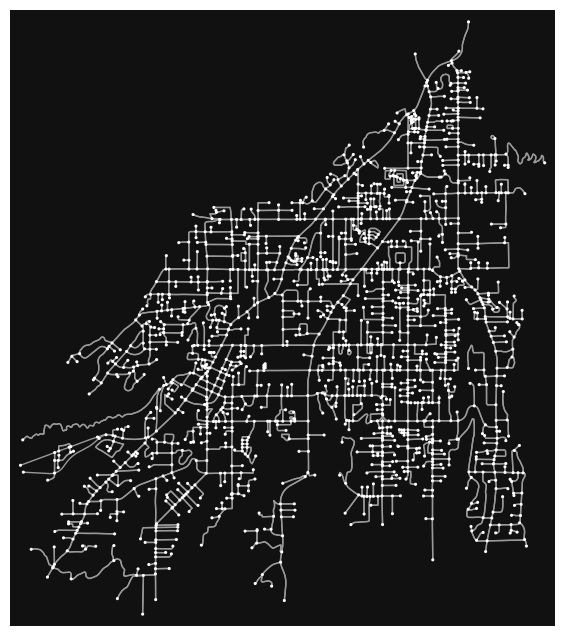

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [14]:
ox.plot_graph(G, node_size=5)

In [15]:
boundary = ox.geocode_to_gdf(place).geometry.iloc[0]
nodes = ox.graph_to_gdfs(G, edges=False)

inside = nodes.within(boundary)
exit_nodes = list(nodes[~inside].index)
home_nodes=list(nodes[inside].index)

print("Homes (intersections inside town):", len(home_nodes))
print("Exits (intersections outside town):", len(exit_nodes))

Homes (intersections inside town): 1822
Exits (intersections outside town): 30


In [16]:
import networkx as nx
from collections import Counter

Gr = G.reverse(copy=True)
dist, paths = nx.multi_source_dijkstra(Gr, sources=exit_nodes, weight="length")

exit_load = Counter()
for h in home_nodes:
    if h in paths:
        exit_load[paths[h][0]] += 1

print("Homes with a route out:", sum(exit_load.values()), "of", len(home_nodes))
print("Busiest exits (exit id, homes using it):")
for node, count in exit_load.most_common(10):
    print(node, count)

Homes with a route out: 1822 of 1822
Busiest exits (exit id, homes using it):
86480320 454
86475701 344
86500303 272
86431098 161
86518494 147
5659704596 112
86520777 104
86526034 74
86502126 55
86387168 43


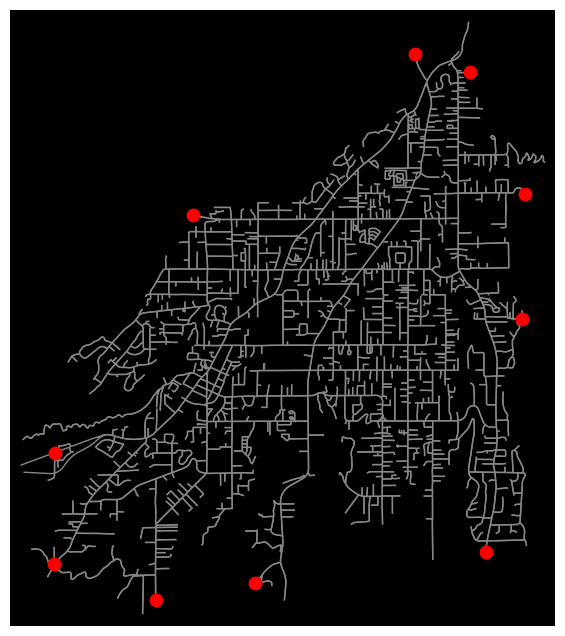

In [17]:
baseline_load = dict(exit_load)

import matplotlib.pyplot as plt

top = [n for n, c in exit_load.most_common(10)]
fig, ax = ox.plot_graph(G, show=False, close=False, node_size=0,
                        edge_color="#888888", bgcolor="black")
ax.scatter([G.nodes[n]["x"] for n in top],
           [G.nodes[n]["y"] for n in top],
           c="red", s=80, zorder=3)
plt.show()

In [18]:
import random
import numpy as np
from scipy.stats import spearmanr

def get_exit_load(graph):
    gr = graph.reverse(copy=True)
    d, p = nx.multi_source_dijkstra(gr, sources=exit_nodes, weight="length")
    load = Counter()
    for h in home_nodes:
        if h in p:
            load[p[h][0]] += 1
    return load, sum(load.values())

def remove_links(graph, edge_list):
    H = graph.copy()
    for u, v, k in edge_list:
        if H.has_edge(u, v, k):
            H.remove_edge(u, v, k)
        if H.has_edge(v, u):
            first_key = list(H[v][u].keys())[0]
            H.remove_edge(v, u, first_key)
    return H

In [19]:
def remove_segments(graph, segment_list):
    H = graph.copy()
    for u, v in segment_list:
        while H.has_edge(u, v):
            H.remove_edge(u, v)
        while H.has_edge(v, u):
            H.remove_edge(v, u)
    return H

segments = list({tuple(sorted((u, v))) for u, v, k in G.edges(keys=True) if u != v})
print("Street segments in the map:", len(segments))
random.seed(42)

for frac in [0.05, 0.10, 0.20, 0.30]:
    cors, unreachable = [], []
    for run in range(20):
        drop = random.sample(segments, int(len(segments) * frac))
        H = remove_segments(G, drop)
        load, reached = get_exit_load(H)
        a = [baseline_load.get(x, 0) for x in exit_nodes]
        b = [load.get(x, 0) for x in exit_nodes]
        cors.append(spearmanr(a, b)[0])
        unreachable.append(1 - reached / len(home_nodes))
    print(f"{int(frac*100)}% of street segments removed: ranking match = {np.nanmean(cors):.2f}, homes cut off = {np.nanmean(unreachable)*100:.1f}%")

Street segments in the map: 2020
5% of street segments removed: ranking match = 0.89, homes cut off = 9.0%
10% of street segments removed: ranking match = 0.86, homes cut off = 23.6%
20% of street segments removed: ranking match = 0.75, homes cut off = 78.7%
30% of street segments removed: ranking match = 0.66, homes cut off = 93.0%


In [20]:
Gr0 = G.reverse(copy=True)
d0, p0 = nx.multi_source_dijkstra(Gr0, sources=exit_nodes, weight="length")

seg_load = Counter()
for h in home_nodes:
    route = p0[h]
    for i in range(len(route) - 1):
        seg_load[tuple(sorted((route[i], route[i + 1])))] += 1

print("Segments used by at least one route:", len(seg_load), "of", len(segments))

a = [baseline_load.get(x, 0) for x in exit_nodes]
for frac in [0.05, 0.10, 0.20, 0.30]:
    k = int(len(segments) * frac)
    busiest = [s for s, c in seg_load.most_common(k)]
    H = remove_segments(G, busiest)
    load, reached = get_exit_load(H)
    b = [load.get(x, 0) for x in exit_nodes]
    print(f"{int(frac*100)}% BUSIEST segments removed ({len(busiest)}): ranking match = {spearmanr(a, b)[0]:.2f}, homes cut off = {(1 - reached / len(home_nodes))*100:.1f}%")

Segments used by at least one route: 1822 of 2020
5% BUSIEST segments removed (101): ranking match = 0.28, homes cut off = 17.8%
10% BUSIEST segments removed (202): ranking match = 0.20, homes cut off = 30.9%
20% BUSIEST segments removed (404): ranking match = 0.08, homes cut off = 97.7%
30% BUSIEST segments removed (606): ranking match = 0.05, homes cut off = 98.6%


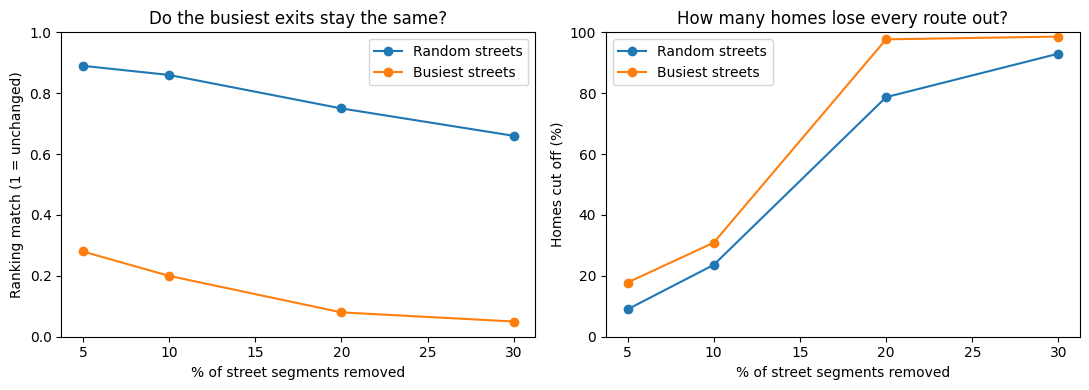

In [21]:
import matplotlib.pyplot as plt

pct = [5, 10, 20, 30]
rand_match = [0.89, 0.86, 0.75, 0.66]
targ_match = [0.28, 0.20, 0.08, 0.05]
rand_cut = [9.0, 23.6, 78.7, 93.0]
targ_cut = [17.8, 30.9, 97.7, 98.6]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(pct, rand_match, marker="o", label="Random streets")
axes[0].plot(pct, targ_match, marker="o", label="Busiest streets")
axes[0].set_title("Do the busiest exits stay the same?")
axes[0].set_xlabel("% of street segments removed")
axes[0].set_ylabel("Ranking match (1 = unchanged)")
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].plot(pct, rand_cut, marker="o", label="Random streets")
axes[1].plot(pct, targ_cut, marker="o", label="Busiest streets")
axes[1].set_title("How many homes lose every route out?")
axes[1].set_xlabel("% of street segments removed")
axes[1].set_ylabel("Homes cut off (%)")
axes[1].set_ylim(0, 100)
axes[1].legend()

plt.tight_layout()
plt.show()